<a href="https://colab.research.google.com/github/usumakikai8-bot/DNN4/blob/main/check_consistency_of_the_dataset_1107.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Imports and configuration

In [ ]:

import csv
import hashlib
import json
import random
import re
from collections import Counter
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
# import torch
# from torch import nn
# from torch.utils.data import DataLoader, Dataset
from google.colab import files


In [ ]:

from google.colab import drive
drive.mount('/content/drive')

In [ ]:

%cd /content/drive/MyDrive/research/DNN6


In [ ]:
%pwd

Use paths that match the current project and dataset environment.

In [ ]:
from pathlib import Path
PROJECT_ROOT = Path.cwd()

DATASET_ROOT = Path(r'/content/drive/MyDrive/research/dataset-dnn6') if Path(r'/content/drive/MyDrive/research/dataset-dnn6').exists() else Path('/content/drive/MyDrive/research/dataset-dnn6')
CATALOG_ROOT = DATASET_ROOT / 'dnn-catalog-1107'
H_CATALOG_FILE = 'JIS_SN_medium_narrow_H_list_DNN.csv'
BOX_CATALOG_FILE = 'BCR_square_tube_list_DNN.csv'
OUTPUT_DIR = PROJECT_ROOT / 'check_consistency_of_dataset_result'
print('PROJECT_ROOT:', PROJECT_ROOT)
print('DATASET_ROOT:', DATASET_ROOT)
print('CATALOG_ROOT:', CATALOG_ROOT)
print('H catalog file:', H_CATALOG_FILE, '/ box catalog file:', BOX_CATALOG_FILE)
print('OUTPUT_DIR:', OUTPUT_DIR)

## Consolidate the data from the three directories—train, val, and test—into a single directory.

In [9]:
import os
import shutil

# ============================================================
# 1. Define paths
# ============================================================

DATASET_ROOT = "/content/drive/MyDrive/research/dataset-dnn6"

train_dir = os.path.join(DATASET_ROOT, "train")
val_dir   = os.path.join(DATASET_ROOT, "val")
test_dir  = os.path.join(DATASET_ROOT, "test")

# Destination directory
consolidated_dir = os.path.join(DATASET_ROOT, "all_data")


# ============================================================
# 2. Create destination directory
# ============================================================

os.makedirs(consolidated_dir, exist_ok=True)


# ============================================================
# 3. Copy files from train, val, and test
# ============================================================

for source_dir in [train_dir, val_dir, test_dir]:

    if not os.path.exists(source_dir):
        print(f"Warning: Directory not found: {source_dir}")
        continue

    for file_name in os.listdir(source_dir):

        source_path = os.path.join(source_dir, file_name)
        destination_path = os.path.join(consolidated_dir, file_name)

        # Only process files
        if os.path.isfile(source_path):

            # Skip if the file already exists at the destination
            if os.path.exists(destination_path):
                print(f"Skipped (already exists): {destination_path}")
                continue

            # Copy the file
            shutil.copy2(source_path, destination_path)
            print(f"Copied: {source_path} -> {destination_path}")


# ============================================================
# 4. Summary
# ============================================================

num_files = len([
    f for f in os.listdir(consolidated_dir)
    if os.path.isfile(os.path.join(consolidated_dir, f))
])

print("\n========================================")
print("Consolidation complete.")
print(f"Destination: {consolidated_dir}")
print(f"Total files in destination: {num_files}")
print("========================================")

Skipped (already exists): /content/drive/MyDrive/research/dataset-dnn6/all_data/F2_X1_8000_Y1_4000_H3000_W6p0_model.csv
Skipped (already exists): /content/drive/MyDrive/research/dataset-dnn6/all_data/F1_X2_9000_Y1_4000_H3000_W6p0_model.csv
Skipped (already exists): /content/drive/MyDrive/research/dataset-dnn6/all_data/F1_X1_7000_Y1_4000_H3000_W7p0_model.csv
Skipped (already exists): /content/drive/MyDrive/research/dataset-dnn6/all_data/F2_X3_4000_Y1_4000_H3000_W6p0_model.csv
Skipped (already exists): /content/drive/MyDrive/research/dataset-dnn6/all_data/F1_X3_9000_Y1_4000_H3000_W6p5_model.csv
Skipped (already exists): /content/drive/MyDrive/research/dataset-dnn6/all_data/F2_X2_9000_Y1_4000_H3000_W6p5_model.csv
Skipped (already exists): /content/drive/MyDrive/research/dataset-dnn6/all_data/F2_X1_6000_Y1_4000_H3000_W6p0_model.csv
Skipped (already exists): /content/drive/MyDrive/research/dataset-dnn6/all_data/F1_X1_5000_Y1_4000_H3000_W7p5_model.csv
Skipped (already exists): /content/drive

## Extract H-beam information from all model CSV files

In [ ]:
# # ============================================================
# # Step 1: Extract H-beam information from all model CSV files
# # (Google Colab)
# # ============================================================
# #
# # Each CSV is a multi-section file ("name=..." blocks), not a flat table.
# # This script reads the "name=S梁断面" block (beam sections per floor/beam
# # code) and the "name=梁符号" block (direction / location / span of each
# # beam code), and combines them with the conditions in the filename.
# #
# # Result: one long-format DataFrame `df_beams`, one row per
# # (file, floor, beam code), saved to beam_dataset.csv.

# import os
# import re
# import glob
# import csv
# import pandas as pd

# # from google.colab import drive
# # drive.mount('/content/drive')

# DATA_DIR   = '/content/drive/MyDrive/research/dataset-dnn6/all_data/'
# OUTPUT_CSV = '/content/drive/MyDrive/research/dataset-dnn6/beam_dataset.csv'


# # ------------------------------------------------------------
# # Filename parser
# #   F5_X6_8000_Y1_4000_H3000_W8p0_model.csv
# #   F = floors, X6_8000 = 6 X-spans of 8000 mm,
# #   Y1_4000 = 1 Y-span of 4000 mm, H3000 = story height,
# #   W8p0 = load 8.0 kN/m2
# # ------------------------------------------------------------
# FILENAME_RE = re.compile(
#     r'F(?P<floors>\d+)_X(?P<nx>\d+)_(?P<x_span>\d+)'
#     r'_Y(?P<ny>\d+)_(?P<y_span>\d+)'
#     r'_H(?P<story_h>\d+)_W(?P<load>[\d]+p?\d*)'
# )


# def parse_filename(file_name):
#     m = FILENAME_RE.search(file_name)
#     if m is None:
#         return None
#     d = m.groupdict()
#     return {
#         'floors':        int(d['floors']),
#         'n_x_spans':     int(d['nx']),
#         'x_span':        int(d['x_span']),
#         'n_y_spans':     int(d['ny']),
#         'y_span':        int(d['y_span']),
#         'story_height':  int(d['story_h']),
#         'load_kN_m2':    float(d['load'].replace('p', '.')),
#     }


# # ------------------------------------------------------------
# # Section reader for the "name=..." block format
# # ------------------------------------------------------------
# def read_sections(path):
#     """
#     Return {section_name: (header_list, [row_list, ...])}.
#     Rows are taken after the '<data>' marker until a blank line.
#     """
#     with open(path, encoding='utf-8-sig', newline='') as f:
#         rows = list(csv.reader(f))

#     sections = {}
#     i = 0
#     while i < len(rows):
#         row = rows[i]
#         if row and row[0].startswith('name='):
#             name = row[0][len('name='):].strip()
#             header = rows[i + 1] if i + 1 < len(rows) else []
#             data = []
#             j = i + 2
#             if j < len(rows) and rows[j] and rows[j][0].strip() == '<data>':
#                 j += 1
#                 while j < len(rows) and any(c.strip() for c in rows[j]):
#                     data.append(rows[j])
#                     j += 1
#             sections[name] = (header, data)
#             i = j
#         else:
#             i += 1
#     return sections


# def section_to_df(sections, name):
#     if name not in sections:
#         return pd.DataFrame()
#     header, data = sections[name]
#     data = [r + [''] * (len(header) - len(r)) for r in data]
#     return pd.DataFrame([r[:len(header)] for r in data], columns=header)


# # ------------------------------------------------------------
# # H-section name parser:  H-294x200x8x12x13  ->  H, B, tw, tf, r
# # ------------------------------------------------------------
# H_SECTION_RE = re.compile(
#     r'H-([\d.]+)x([\d.]+)x([\d.]+)x([\d.]+)(?:x([\d.]+))?'
# )


# def parse_h_section(text):
#     m = H_SECTION_RE.search(text or '')
#     if m is None:
#         return None
#     H, B, tw, tf, r = m.groups()
#     return {
#         'H': float(H), 'B': float(B), 'tw': float(tw), 'tf': float(tf),
#         'r': float(r) if r else None,
#     }


# # ------------------------------------------------------------
# # Extract beam rows from one file
# # ------------------------------------------------------------
# def extract_beams_from_file(path):
#     file_name = os.path.basename(path)
#     cond = parse_filename(file_name)
#     if cond is None:
#         raise ValueError('filename does not match expected pattern')

#     sections = read_sections(path)

#     beams = section_to_df(sections, 'S梁断面')
#     if beams.empty:
#         raise ValueError('section "S梁断面" not found')

#     codes = section_to_df(sections, '梁符号')   # direction / location per code
#     code_info = {}
#     for _, r in codes.iterrows():
#         code_info[r['梁符号']] = {
#             'direction': r['方向'],      # X or Y
#             'location':  r['配置'],      # 外周 (perimeter) / 内部 (interior)
#         }

#     # Floor label -> floor index (RFL is the roof level = floors + 1)
#     def floor_index(label):
#         if label == 'RFL':
#             return cond['floors'] + 1
#         m = re.match(r'(\d+)FL', label)
#         return int(m.group(1)) if m else None

#     out = []
#     for _, r in beams.iterrows():
#         if r['鉄骨形状'] != 'H':
#             continue
#         sec = parse_h_section(r['鉄骨登録形状'])
#         if sec is None:
#             continue
#         info = code_info.get(r['梁符号'], {})
#         out.append({
#             'file_name':      file_name,
#             **cond,
#             'floor_label':    r['層'],
#             'floor_index':    floor_index(r['層']),
#             'beam_code':      r['梁符号'],
#             'direction':      info.get('direction'),
#             'location':       info.get('location'),
#             'section_name':   r['鉄骨登録形状'],
#             **sec,
#             'nominal_H':      float(r['呼びH(mm)']),
#             'nominal_B':      float(r['呼びB(mm)']),
#             'n_members':      int(r['本数']),
#             'member_span_mm': float(r['スパン長(mm)']),
#         })
#     return out


# # ------------------------------------------------------------
# # Run over the whole directory
# # ------------------------------------------------------------
# all_rows, failed = [], []
# files = sorted(glob.glob(os.path.join(DATA_DIR, '*.csv')))
# print(f'{len(files)} CSV files found in {DATA_DIR}')

# for path in files:
#     try:
#         all_rows.extend(extract_beams_from_file(path))
#     except Exception as e:
#         failed.append((os.path.basename(path), str(e)))

# df_beams = pd.DataFrame(all_rows)

# # Round load to an integer-friendly label for grouping/plotting (w=6,7,8,...)
# df_beams['load_label'] = df_beams['load_kN_m2'].map(lambda v: f'w={v:g}')

# df_beams.to_csv(OUTPUT_CSV, index=False, encoding='utf-8-sig')

# # ------------------------------------------------------------
# # Report
# # ------------------------------------------------------------
# print(f'Extracted {len(df_beams)} beam rows from '
#       f'{df_beams["file_name"].nunique()} files -> {OUTPUT_CSV}')
# if failed:
#     print(f'\n{len(failed)} files failed:')
#     for name, msg in failed[:20]:
#         print(f'  {name}: {msg}')

# print('\nAvailable conditions:')
# for col in ['floors', 'n_x_spans', 'x_span', 'n_y_spans', 'y_span',
#             'story_height', 'load_kN_m2']:
#     print(f'  {col:13s}: {sorted(df_beams[col].unique())}')

# print('\nPreview:')
# print(df_beams[['file_name', 'floor_label', 'beam_code', 'direction',
#                 'location', 'section_name', 'H', 'member_span_mm']].head(15)
#       .to_string(index=False))

In [10]:
# # Paste your copied path here
# path = '/content/drive/MyDrive/research/dataset-dnn6/beam_dataset.csv'
# df = pd.read_csv(path)

# df.head()

,file_name,floors,n_x_spans,x_span,n_y_spans,y_span,story_height,load_kN_m2,floor_label,floor_index,...,H,B,tw,tf,r,nominal_H,nominal_B,n_members,member_span_mm,load_label
0,F1_X1_4000_Y1_4000_H3000_W6p0_model.csv,1,1,4000,1,4000,3000,6.0,RFL,2,...,148.0,100.0,6.0,9.0,8.0,150.0,100.0,2,4000.0,w=6
1,F1_X1_4000_Y1_4000_H3000_W6p0_model.csv,1,1,4000,1,4000,3000,6.0,RFL,2,...,148.0,100.0,6.0,9.0,8.0,150.0,100.0,2,4000.0,w=6
2,F1_X1_4000_Y1_4000_H3000_W6p5_model.csv,1,1,4000,1,4000,3000,6.5,RFL,2,...,148.0,100.0,6.0,9.0,8.0,150.0,100.0,2,4000.0,w=6.5
3,F1_X1_4000_Y1_4000_H3000_W6p5_model.csv,1,1,4000,1,4000,3000,6.5,RFL,2,...,148.0,100.0,6.0,9.0,8.0,150.0,100.0,2,4000.0,w=6.5
4,F1_X1_4000_Y1_4000_H3000_W7p0_model.csv,1,1,4000,1,4000,3000,7.0,RFL,2,...,148.0,100.0,6.0,9.0,8.0,150.0,100.0,2,4000.0,w=7


In [11]:
df

,file_name,floors,n_x_spans,x_span,n_y_spans,y_span,story_height,load_kN_m2,floor_label,floor_index,...,H,B,tw,tf,r,nominal_H,nominal_B,n_members,member_span_mm,load_label
0,F1_X1_4000_Y1_4000_H3000_W6p0_model.csv,1,1,4000,1,4000,3000,6.0,RFL,2,...,148.0,100.0,6.0,9.0,8.0,150.0,100.0,2,4000.0,w=6
1,F1_X1_4000_Y1_4000_H3000_W6p0_model.csv,1,1,4000,1,4000,3000,6.0,RFL,2,...,148.0,100.0,6.0,9.0,8.0,150.0,100.0,2,4000.0,w=6
2,F1_X1_4000_Y1_4000_H3000_W6p5_model.csv,1,1,4000,1,4000,3000,6.5,RFL,2,...,148.0,100.0,6.0,9.0,8.0,150.0,100.0,2,4000.0,w=6.5
3,F1_X1_4000_Y1_4000_H3000_W6p5_model.csv,1,1,4000,1,4000,3000,6.5,RFL,2,...,148.0,100.0,6.0,9.0,8.0,150.0,100.0,2,4000.0,w=6.5
4,F1_X1_4000_Y1_4000_H3000_W7p0_model.csv,1,1,4000,1,4000,3000,7.0,RFL,2,...,148.0,100.0,6.0,9.0,8.0,150.0,100.0,2,4000.0,w=7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7645,F5_X6_9000_Y1_4000_H3000_W8p0_model.csv,5,6,9000,1,4000,3000,8.0,3FL,3,...,500.0,200.0,10.0,16.0,13.0,500.0,200.0,2,4000.0,w=8
7646,F5_X6_9000_Y1_4000_H3000_W8p0_model.csv,5,6,9000,1,4000,3000,8.0,3FL,3,...,500.0,200.0,10.0,16.0,13.0,500.0,200.0,5,4000.0,w=8
7647,F5_X6_9000_Y1_4000_H3000_W8p0_model.csv,5,6,9000,1,4000,3000,8.0,2FL,2,...,500.0,200.0,10.0,16.0,13.0,500.0,200.0,12,9000.0,w=8
7648,F5_X6_9000_Y1_4000_H3000_W8p0_model.csv,5,6,9000,1,4000,3000,8.0,2FL,2,...,500.0,200.0,10.0,16.0,13.0,500.0,200.0,2,4000.0,w=8


In [12]:
# ============================================================
# Step 1: Extract H-beam AND box-column information from all
# model CSV files (Google Colab)
# ============================================================
#
# Each CSV is a multi-section file ("name=..." blocks):
#   name=S梁断面  -> beam sections per floor / beam code
#   name=S柱断面  -> column sections per floor / column code
#   name=梁符号   -> direction / location of each beam code
#   name=柱符号   -> location of each column code
#
# Output: one row per component (file, slot), where
#   slot = "beam:RFL:GX1"  or  "column:1FL:C1"
# (same slot naming as the prediction table).
#
# Duplicate handling:
#   * A (file_name, slot) pair is never extracted twice.
#   * If OUTPUT_CSV already exists, every (file_name, slot) already
#     stored in it is skipped, and only new components are appended.

import os
import re
import csv
import glob
import pandas as pd

# from google.colab import drive
# drive.mount('/content/drive')

DATA_DIR   = '/content/drive/MyDrive/research/dataset-dnn6/all_data/'
OUTPUT_CSV = '/content/drive/MyDrive/research/dataset-dnn6/member_dataset.csv'


# ------------------------------------------------------------
# Filename parser
#   F5_X6_8000_Y1_4000_H3000_W8p0_model.csv
# ------------------------------------------------------------
FILENAME_RE = re.compile(
    r'F(?P<floors>\d+)_X(?P<nx>\d+)_(?P<x_span>\d+)'
    r'_Y(?P<ny>\d+)_(?P<y_span>\d+)'
    r'_H(?P<story_h>\d+)_W(?P<load>\d+p?\d*)'
)


def parse_filename(file_name):
    m = FILENAME_RE.search(file_name)
    if m is None:
        return None
    d = m.groupdict()
    return {
        'floors':       int(d['floors']),
        'n_x_spans':    int(d['nx']),
        'x_span':       int(d['x_span']),
        'n_y_spans':    int(d['ny']),
        'y_span':       int(d['y_span']),
        'story_height': int(d['story_h']),
        'load_kN_m2':   float(d['load'].replace('p', '.')),
    }


# ------------------------------------------------------------
# Section reader for the "name=..." block format
# ------------------------------------------------------------
def read_sections(path):
    with open(path, encoding='utf-8-sig', newline='') as f:
        rows = list(csv.reader(f))

    sections, i = {}, 0
    while i < len(rows):
        row = rows[i]
        if row and row[0].startswith('name='):
            name = row[0][len('name='):].strip()
            header = rows[i + 1] if i + 1 < len(rows) else []
            data, j = [], i + 2
            if j < len(rows) and rows[j] and rows[j][0].strip() == '<data>':
                j += 1
                while j < len(rows) and any(c.strip() for c in rows[j]):
                    data.append(rows[j])
                    j += 1
            sections[name] = (header, data)
            i = j
        else:
            i += 1
    return sections


def section_to_df(sections, name):
    if name not in sections:
        return pd.DataFrame()
    header, data = sections[name]
    data = [(r + [''] * len(header))[:len(header)] for r in data]
    return pd.DataFrame(data, columns=header)


# ------------------------------------------------------------
# Section-name parsers
#   H-294x200x8x12x13  -> H, B, tw, tf, r
#   □-350x350x12x30    -> D, t   (box column; shown as "B-..." in the
#                                 prediction table, so converted to match)
# ------------------------------------------------------------
H_RE   = re.compile(r'H-([\d.]+)x([\d.]+)x([\d.]+)x([\d.]+)(?:x([\d.]+))?')
BOX_RE = re.compile(r'[□B]-([\d.]+)x([\d.]+)x([\d.]+)x([\d.]+)')


def to_float(s):
    return float(s) if s not in (None, '') else None


def floor_index_of(label, n_floors):
    if label == 'RFL':
        return n_floors + 1
    m = re.match(r'(\d+)FL', label)
    return int(m.group(1)) if m else None


# ------------------------------------------------------------
# Extract all components from one file
# ------------------------------------------------------------
def extract_components_from_file(path):
    file_name = os.path.basename(path)
    cond = parse_filename(file_name)
    if cond is None:
        raise ValueError('filename does not match expected pattern')
    sections = read_sections(path)
    out = []

    # ---------------- beams ----------------
    beams = section_to_df(sections, 'S梁断面')
    codes = section_to_df(sections, '梁符号')
    beam_info = {r['梁符号']: {'direction': r['方向'], 'location': r['配置']}
                 for _, r in codes.iterrows()}

    for _, r in beams.iterrows():
        if r['鉄骨形状'] != 'H':
            continue
        m = H_RE.search(r['鉄骨登録形状'])
        if m is None:
            continue
        H, B, tw, tf, rr = m.groups()
        info = beam_info.get(r['梁符号'], {})
        out.append({
            'file_name':     file_name,
            'slot':          f"beam:{r['層']}:{r['梁符号']}",
            'member_type':   'beam',
            'section_type':  'h',
            **cond,
            'floor_label':   r['層'],
            'floor_index':   floor_index_of(r['層'], cond['floors']),
            'code':          r['梁符号'],
            'direction':     info.get('direction'),
            'location':      info.get('location'),
            'catalog':       r['鉄骨登録形状'],
            'H': float(H), 'B': float(B), 'tw': float(tw), 'tf': float(tf),
            'r': to_float(rr),
            'D': None, 't': None,
            'nominal_H':     to_float(r['呼びH(mm)']),
            'nominal_B':     to_float(r['呼びB(mm)']),
            'n_members':     int(r['本数']),
            'member_length_mm': to_float(r['スパン長(mm)']),
        })

    # ---------------- columns ----------------
    cols = section_to_df(sections, 'S柱断面')
    col_codes = section_to_df(sections, '柱符号')
    col_info = {r['柱符号']: {'location': r['配置']}
                for _, r in col_codes.iterrows()}

    for _, r in cols.iterrows():
        m = BOX_RE.search(r['鉄骨断面'])
        if m is None:
            continue
        D, D2, t, rr = m.groups()
        info = col_info.get(r['柱符号'], {})
        out.append({
            'file_name':     file_name,
            'slot':          f"column:{r['階']}:{r['柱符号']}",
            'member_type':   'column',
            'section_type':  'box',
            **cond,
            'floor_label':   r['階'],
            'floor_index':   floor_index_of(r['階'], cond['floors']),
            'code':          r['柱符号'],
            'direction':     None,
            'location':      info.get('location'),
            'catalog':       f'B-{D}x{D2}x{t}x{rr}',   # same style as df
            'H': None, 'B': None, 'tw': None, 'tf': None,
            'r': to_float(rr),            # last number (=2.5 t here)
            'D': float(D), 't': float(t),
            'nominal_H':     None,
            'nominal_B':     to_float(r['呼びD(mm)']),  # nominal D
            'n_members':     int(r['本数']),
            'member_length_mm': to_float(r['部材長(mm)']),
        })

    return out


# ------------------------------------------------------------
# Load what has already been extracted (if any)
# ------------------------------------------------------------
if os.path.exists(OUTPUT_CSV):
    df_existing = pd.read_csv(OUTPUT_CSV, encoding='utf-8-sig')
    already = set(zip(df_existing['file_name'], df_existing['slot']))
    print(f'Existing output found: {len(df_existing)} components already extracted')
else:
    df_existing = pd.DataFrame()
    already = set()


# ------------------------------------------------------------
# Run over the directory, skipping components already extracted
# ------------------------------------------------------------
new_rows, failed, n_skipped = [], [], 0
files = sorted(glob.glob(os.path.join(DATA_DIR, '*.csv')))
print(f'{len(files)} CSV files found in {DATA_DIR}')

for path in files:
    try:
        rows = extract_components_from_file(path)
    except Exception as e:
        failed.append((os.path.basename(path), str(e)))
        continue

    for row in rows:
        key = (row['file_name'], row['slot'])
        if key in already:
            n_skipped += 1
            continue
        already.add(key)          # also prevents duplicates within this run
        new_rows.append(row)

df_new = pd.DataFrame(new_rows)
member_df = pd.concat([df_existing, df_new], ignore_index=True)

# Safety net: guarantee one row per (file_name, slot)
member_df = member_df.drop_duplicates(subset=['file_name', 'slot'], keep='first')
member_df['load_label'] = member_df['load_kN_m2'].map(lambda v: f'w={v:g}')

member_df.to_csv(OUTPUT_CSV, index=False, encoding='utf-8-sig')


# ------------------------------------------------------------
# Report
# ------------------------------------------------------------
print(f'\nNew components extracted : {len(df_new)}')
print(f'Skipped (already extracted): {n_skipped}')
print(f'Total in {OUTPUT_CSV}: {len(member_df)} '
      f'({member_df["file_name"].nunique()} files)')
print(member_df['member_type'].value_counts().to_string())

if failed:
    print(f'\n{len(failed)} files failed:')
    for name, msg in failed[:20]:
        print(f'  {name}: {msg}')

print('\nAvailable conditions:')
for col in ['floors', 'n_x_spans', 'x_span', 'n_y_spans', 'y_span',
            'story_height', 'load_kN_m2']:
    print(f'  {col:13s}: {sorted(member_df[col].unique().tolist())}')

print('\nPreview:')
print(member_df[['file_name', 'slot', 'section_type', 'catalog',
                 'H', 'B', 'D', 't']].head(20).to_string(index=False))

900 CSV files found in /content/drive/MyDrive/research/dataset-dnn6/all_data/

New components extracted : 10346
Skipped (already extracted): 0
Total in /content/drive/MyDrive/research/dataset-dnn6/member_dataset.csv: 10346 (899 files)
member_type
beam      7647
column    2699

Available conditions:
  floors       : [1, 2, 3, 4, 5]
  n_x_spans    : [1, 2, 3, 4, 5, 6]
  x_span       : [4000, 5000, 6000, 7000, 8000, 9000]
  n_y_spans    : [1]
  y_span       : [4000]
  story_height : [3000]
  load_kN_m2   : [6.0, 6.5, 7.0, 7.5, 8.0]

Preview:
                              file_name          slot section_type         catalog     H     B     D   t
F1_X1_4000_Y1_4000_H3000_W6p0_model.csv  beam:RFL:GX1            h H-148x100x6x9x8 148.0 100.0   NaN NaN
F1_X1_4000_Y1_4000_H3000_W6p0_model.csv  beam:RFL:GY1            h H-148x100x6x9x8 148.0 100.0   NaN NaN
F1_X1_4000_Y1_4000_H3000_W6p0_model.csv column:1FL:C1          box  B-150x150x6x15   NaN   NaN 150.0 6.0
F1_X1_4000_Y1_4000_H3000_W6p5_model

## Read the CSV

In [13]:
# Paste your copied path here
path = '/content/drive/MyDrive/research/dataset-dnn6/member_dataset.csv'
df = pd.read_csv(path)

df.head()

,file_name,slot,member_type,section_type,floors,n_x_spans,x_span,n_y_spans,y_span,story_height,...,tw,tf,r,D,t,nominal_H,nominal_B,n_members,member_length_mm,load_label
0,F1_X1_4000_Y1_4000_H3000_W6p0_model.csv,beam:RFL:GX1,beam,h,1,1,4000,1,4000,3000,...,6.0,9.0,8.0,NaN,NaN,150.0,100.0,2,4000.0,w=6
1,F1_X1_4000_Y1_4000_H3000_W6p0_model.csv,beam:RFL:GY1,beam,h,1,1,4000,1,4000,3000,...,6.0,9.0,8.0,NaN,NaN,150.0,100.0,2,4000.0,w=6
2,F1_X1_4000_Y1_4000_H3000_W6p0_model.csv,column:1FL:C1,column,box,1,1,4000,1,4000,3000,...,NaN,NaN,15.0,150.0,6.0,NaN,150.0,4,3000.0,w=6
3,F1_X1_4000_Y1_4000_H3000_W6p5_model.csv,beam:RFL:GX1,beam,h,1,1,4000,1,4000,3000,...,6.0,9.0,8.0,NaN,NaN,150.0,100.0,2,4000.0,w=6.5
4,F1_X1_4000_Y1_4000_H3000_W6p5_model.csv,beam:RFL:GY1,beam,h,1,1,4000,1,4000,3000,...,6.0,9.0,8.0,NaN,NaN,150.0,100.0,2,4000.0,w=6.5


In [15]:
print(df)

                                     file_name           slot member_type  \
0      F1_X1_4000_Y1_4000_H3000_W6p0_model.csv   beam:RFL:GX1        beam   
1      F1_X1_4000_Y1_4000_H3000_W6p0_model.csv   beam:RFL:GY1        beam   
2      F1_X1_4000_Y1_4000_H3000_W6p0_model.csv  column:1FL:C1      column   
3      F1_X1_4000_Y1_4000_H3000_W6p5_model.csv   beam:RFL:GX1        beam   
4      F1_X1_4000_Y1_4000_H3000_W6p5_model.csv   beam:RFL:GY1        beam   
...                                        ...            ...         ...   
10341  F5_X6_9000_Y1_4000_H3000_W8p0_model.csv  column:5FL:C1      column   
10342  F5_X6_9000_Y1_4000_H3000_W8p0_model.csv  column:4FL:C1      column   
10343  F5_X6_9000_Y1_4000_H3000_W8p0_model.csv  column:3FL:C1      column   
10344  F5_X6_9000_Y1_4000_H3000_W8p0_model.csv  column:2FL:C1      column   
10345  F5_X6_9000_Y1_4000_H3000_W8p0_model.csv  column:1FL:C1      column   

      section_type  floors  n_x_spans  x_span  n_y_spans  y_span  \
0      

In [18]:
folder_path = '/content/drive/MyDrive/research/dataset-dnn6/all_data'
file_count = len([f for f in os.listdir(folder_path) if os.path.isfile(os.path.join(folder_path, f))])
print(f"Total files: {file_count}")

Total files: 900


In [20]:
#os.listdir(folder_path)

In [24]:
print(df.head())

                                 file_name           slot member_type  \
0  F1_X1_4000_Y1_4000_H3000_W6p0_model.csv   beam:RFL:GX1        beam   
1  F1_X1_4000_Y1_4000_H3000_W6p0_model.csv   beam:RFL:GY1        beam   
2  F1_X1_4000_Y1_4000_H3000_W6p0_model.csv  column:1FL:C1      column   
3  F1_X1_4000_Y1_4000_H3000_W6p5_model.csv   beam:RFL:GX1        beam   
4  F1_X1_4000_Y1_4000_H3000_W6p5_model.csv   beam:RFL:GY1        beam   

  section_type  floors  n_x_spans  x_span  n_y_spans  y_span  story_height  \
0            h       1          1    4000          1    4000          3000   
1            h       1          1    4000          1    4000          3000   
2          box       1          1    4000          1    4000          3000   
3            h       1          1    4000          1    4000          3000   
4            h       1          1    4000          1    4000          3000   

   ...   tw   tf     r      D    t nominal_H nominal_B  n_members  \
0  ...  6.0  9.0   8.0 

In [25]:
print(df.columns)

Index(['file_name', 'slot', 'member_type', 'section_type', 'floors',
       'n_x_spans', 'x_span', 'n_y_spans', 'y_span', 'story_height',
       'load_kN_m2', 'floor_label', 'floor_index', 'code', 'direction',
       'location', 'catalog', 'H', 'B', 'tw', 'tf', 'r', 'D', 't', 'nominal_H',
       'nominal_B', 'n_members', 'member_length_mm', 'load_label'],
      dtype='object')


In [26]:
print(df.columns.tolist())

['file_name', 'slot', 'member_type', 'section_type', 'floors', 'n_x_spans', 'x_span', 'n_y_spans', 'y_span', 'story_height', 'load_kN_m2', 'floor_label', 'floor_index', 'code', 'direction', 'location', 'catalog', 'H', 'B', 'tw', 'tf', 'r', 'D', 't', 'nominal_H', 'nominal_B', 'n_members', 'member_length_mm', 'load_label']


## Generate graphs

In [22]:
# ------------------------------------------------------------
# Settings
# ------------------------------------------------------------
DATASET_CSV = '/content/drive/MyDrive/research/dataset-dnn6/member_dataset.csv'
OUTPUT_DIR  = '/content/drive/MyDrive/research/dataset-dnn6/plots'

## Plot H vs Span

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saved graph to: /content/drive/MyDrive/research/dataset-dnn6/plots/Beam_H_vs_X_Span_by_Load.png

Selected condition:
  floors       : 1
  n_x_spans    : 1
  n_y_spans    : 1
  y_span       : 4000
  story_height : 3000
  floor_label  : RFL
  code         : GX1
  loads        : [6.0, 6.5, 7.0, 7.5, 8.0]
  spans        : [4000, 5000, 6000, 7000, 8000, 9000]

H table (rows = span, columns = load):
load_kN_m2    6.0    6.5    7.0    7.5    8.0
x_span                                       
4000        148.0  148.0  148.0  148.0  148.0
5000        194.0  194.0  194.0  194.0  194.0
6000        194.0  194.0  194.0  194.0  194.0
7000        194.0  194.0  194.0  244.0  244.0
8000        244.0  244.0  244.0  244.0  244.0
9000        294.0  294.0  294.0  294.0  294.0

Consistency check:
  OK - H never decreases with span or with load.

Other candidate conditions (top 10 by coverage):
 floors  n_x_spans  n_y_spans  y_span  story_height floor_label code  n_points  n_spans  n_loads
      1          1 

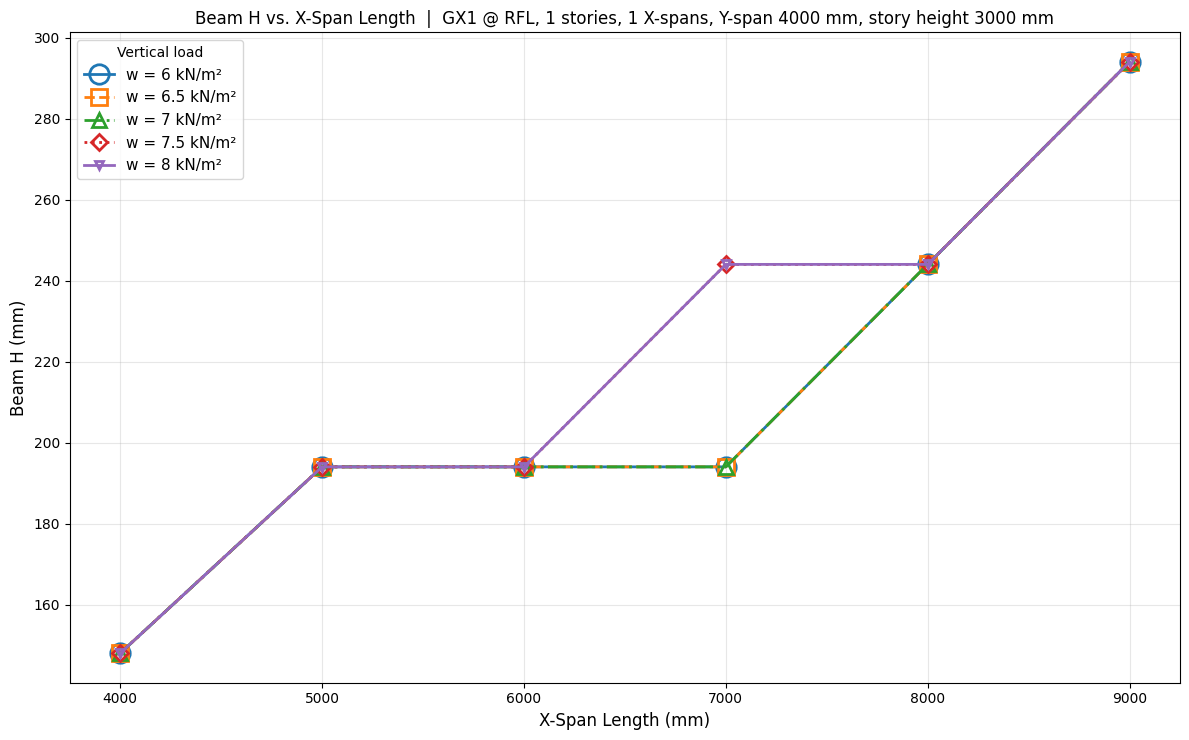

In [21]:
# ============================================================
# Step 2: Plot beam H vs. X-span length, one line per load (w)
# (Google Colab)  -- consistency check of the training data
# ============================================================
#
# Uses the table produced by extract_member_data.py
# (member_df, or member_dataset.csv). Plots the TRUE (training-data)
# H of one fixed beam role against span length, with the loads
# (w=6, 7, 8, ...) combined in a single graph, and checks:
#   (a) H is non-decreasing as span length increases (for each load)
#   (b) H is non-decreasing as load increases     (for each span)
# Violations are circled in the graph and listed in the printout.

import os
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D



# Which beam to examine. None = choose automatically (the condition
# having the most (span, load) combinations; ties -> alphabetical).
FLOORS       = None     # e.g. 5      (number of stories of the building)
N_X_SPANS    = None     # e.g. 6
N_Y_SPANS    = None     # e.g. 1
Y_SPAN       = None     # e.g. 4000
STORY_HEIGHT = None     # e.g. 3000
FLOOR_LABEL  = None     # e.g. '3FL' or 'RFL'
BEAM_CODE    = None     # e.g. 'GX1'
LOADS        = None     # e.g. [6.0, 7.0, 8.0]  (None = all loads found)

# ------------------------------------------------------------
# Load data (re-use member_df if it is already in memory)
# ------------------------------------------------------------
try:
    data = member_df.copy()
except NameError:
    data = pd.read_csv(DATASET_CSV, encoding='utf-8-sig')

# X-direction H-beams only: their length equals the X-span, so
# "H vs. span length" is meaningful. (Y beams have a fixed Y-span.)
beams = data[
    (data['member_type'] == 'beam') &
    (data['section_type'] == 'h') &
    (data['direction'] == 'X')
].dropna(subset=['H', 'x_span', 'load_kN_m2']).copy()

if LOADS is not None:
    beams = beams[beams['load_kN_m2'].isin(LOADS)]

# ------------------------------------------------------------
# Choose the beam role / building condition to compare
# ------------------------------------------------------------
fixed_cols = ['floors', 'n_x_spans', 'n_y_spans', 'y_span',
              'story_height', 'floor_label', 'code']

overrides = {
    'floors': FLOORS, 'n_x_spans': N_X_SPANS, 'n_y_spans': N_Y_SPANS,
    'y_span': Y_SPAN, 'story_height': STORY_HEIGHT,
    'floor_label': FLOOR_LABEL, 'code': BEAM_CODE,
}
for col, val in overrides.items():
    if val is not None:
        beams = beams[beams[col] == val]

if beams.empty:
    raise ValueError('No X-direction H-beam data match the settings.')

coverage = (
    beams.groupby(fixed_cols)
         .agg(n_points=('H', 'size'),
              n_spans=('x_span', 'nunique'),
              n_loads=('load_kN_m2', 'nunique'))
         .reset_index()
         .sort_values(['n_points', 'n_loads', 'n_spans'] + fixed_cols,
                      ascending=[False, False, False] + [True] * len(fixed_cols))
)
chosen = coverage.iloc[0]
cond = {c: chosen[c] for c in fixed_cols}

sel = beams.copy()
for c, v in cond.items():
    sel = sel[sel[c] == v]

# One point per (span, load)
sel = (sel.sort_values(['load_kN_m2', 'x_span', 'file_name'])
          .drop_duplicates(subset=['load_kN_m2', 'x_span'], keep='first'))

loads = sorted(sel['load_kN_m2'].unique())

# ------------------------------------------------------------
# Consistency checks
# ------------------------------------------------------------
violations = []   # (type, load, span_from, span_to, H_from, H_to)

# (a) H should not decrease as span increases (per load)
for w in loads:
    g = sel[sel['load_kN_m2'] == w].sort_values('x_span')
    prev = None
    for _, r in g.iterrows():
        if prev is not None and r['H'] < prev['H']:
            violations.append(('span', w, prev['x_span'], r['x_span'],
                               prev['H'], r['H'], r['file_name']))
        prev = r

# (b) H should not decrease as load increases (per span)
for s in sorted(sel['x_span'].unique()):
    g = sel[sel['x_span'] == s].sort_values('load_kN_m2')
    prev = None
    for _, r in g.iterrows():
        if prev is not None and r['H'] < prev['H']:
            violations.append(('load', r['load_kN_m2'], s, s,
                               prev['H'], r['H'], r['file_name']))
        prev = r

# Points to circle in the graph (the later point of each violation)
bad_points = {(v[1], v[3]) for v in violations if v[0] == 'span'} | \
             {(v[1], v[3]) for v in violations if v[0] == 'load'}

# ------------------------------------------------------------
# Plot: all loads in one graph
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 7.5))

styles = [  # (color, marker, linestyle)
    ('tab:blue',   'o', '-'),
    ('tab:orange', 's', '--'),
    ('tab:green',  '^', '-.'),
    ('tab:red',    'D', ':'),
    ('tab:purple', 'v', '-'),
    ('tab:brown',  'P', '--'),
]

for k, w in enumerate(loads):
    g = sel[sel['load_kN_m2'] == w].sort_values('x_span')
    color, marker, ls = styles[k % len(styles)]
    # larger markers for the first loads so overlapping points stay visible
    msize = max(6, 14 - 2 * k)
    ax.plot(g['x_span'], g['H'], color=color, marker=marker, linestyle=ls,
            linewidth=2, markersize=msize, markerfacecolor='none',
            markeredgewidth=2, label=f'w = {w:g} kN/m²')

# Circle the violating points
for (w, s) in bad_points:
    row = sel[(sel['load_kN_m2'] == w) & (sel['x_span'] == s)]
    ax.scatter(row['x_span'], row['H'], s=420, facecolors='none',
               edgecolors='red', linewidths=2.5, zorder=5)

main_legend = ax.legend(loc='upper left', fontsize=11, title='Vertical load')
if bad_points:
    ax.add_artist(main_legend)
    ax.legend(handles=[Line2D([0], [0], marker='o', color='none',
                              markerfacecolor='none', markeredgecolor='red',
                              markeredgewidth=2.5, markersize=14,
                              label='Non-monotonic point')],
              loc='lower right', fontsize=10)

ax.set_xlabel('X-Span Length (mm)', fontsize=12)
ax.set_ylabel('Beam H (mm)', fontsize=12)
ax.set_title(
    f'Beam H vs. X-Span Length  |  {cond["code"]} @ {cond["floor_label"]}, '
    f'{int(cond["floors"])} stories, {int(cond["n_x_spans"])} X-spans, '
    f'Y-span {int(cond["y_span"])} mm, story height {int(cond["story_height"])} mm',
    fontsize=12)
ax.grid(True, alpha=0.3)
plt.tight_layout()

os.makedirs(OUTPUT_DIR, exist_ok=True)
output_path = os.path.join(OUTPUT_DIR, 'Beam_H_vs_X_Span_by_Load.png')
plt.savefig(output_path, dpi=300, bbox_inches='tight')

try:
    from google.colab import files
    files.download(output_path)
except ImportError:
    pass

# ------------------------------------------------------------
# Report
# ------------------------------------------------------------
print(f'Saved graph to: {output_path}')
print('\nSelected condition:')
for c, v in cond.items():
    print(f'  {c:13s}: {v}')
print(f'  loads        : {[float(w) for w in loads]}')
print(f'  spans        : {sorted(sel["x_span"].unique().tolist())}')

print('\nH table (rows = span, columns = load):')
print(sel.pivot(index='x_span', columns='load_kN_m2', values='H')
         .to_string())

print('\nConsistency check:')
if not violations:
    print('  OK - H never decreases with span or with load.')
else:
    print(f'  {len(violations)} violation(s) found:')
    for kind, w, s0, s1, h0, h1, fname in violations:
        if kind == 'span':
            print(f'  [span] w={w:g}: span {s0:g} -> {s1:g} mm, '
                  f'H {h0:g} -> {h1:g} mm   ({fname})')
        else:
            print(f'  [load] span={s0:g} mm: H drops to {h1:g} mm at '
                  f'w={w:g} (from {h0:g} mm at lower load)   ({fname})')

print('\nOther candidate conditions (top 10 by coverage):')
print(coverage.head(10).to_string(index=False))

plt.show()

## Plot H vs load

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saved graph to: /content/drive/MyDrive/research/dataset-dnn6/plots/Beam_H_vs_Load_by_X_Span.png

Selected condition:
  floors       : 1
  n_x_spans    : 1
  n_y_spans    : 1
  y_span       : 4000
  story_height : 3000
  floor_label  : RFL
  code         : GX1
  loads        : [6.0, 6.5, 7.0, 7.5, 8.0]
  spans        : [4000, 5000, 6000, 7000, 8000, 9000]

H table (rows = load, columns = X-span):
x_span       4000   5000   6000   7000   8000   9000
load_kN_m2                                          
6.0         148.0  194.0  194.0  194.0  244.0  294.0
6.5         148.0  194.0  194.0  194.0  244.0  294.0
7.0         148.0  194.0  194.0  194.0  244.0  294.0
7.5         148.0  194.0  194.0  244.0  244.0  294.0
8.0         148.0  194.0  194.0  244.0  244.0  294.0

Consistency check:
  OK - H never decreases with span or with load.

Other candidate conditions (top 10 by coverage):
 floors  n_x_spans  n_y_spans  y_span  story_height floor_label code  n_points  n_spans  n_loads
      1       

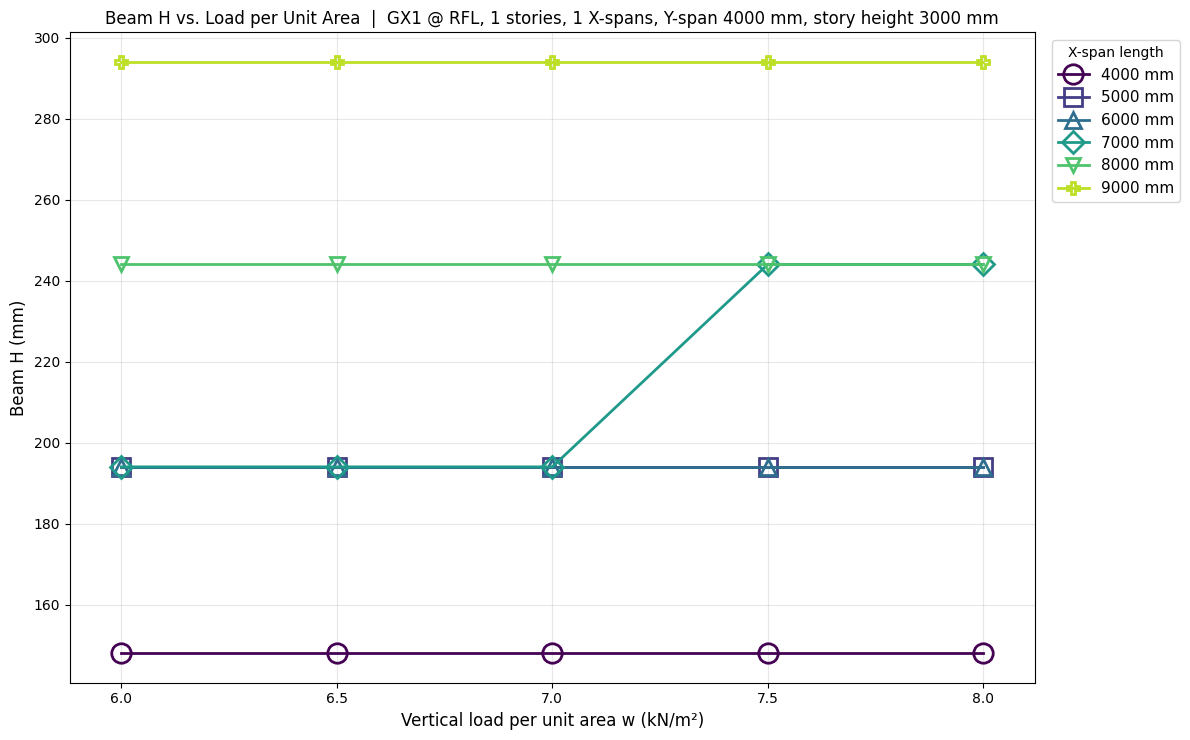

In [23]:
# ============================================================
# Step 3: Plot beam H vs. load per unit area, one line per X-span
# (Google Colab)  -- consistency check of the training data
# ============================================================
#
# Uses the table produced by extract_member_data.py
# (member_df, or member_dataset.csv). Plots the TRUE (training-data)
# H of one fixed beam role against the vertical load per unit area,
# with one line per X-span length in a single graph, and checks:
#   (a) H is non-decreasing as load increases     (for each span)
#   (b) H is non-decreasing as span length increases (for each load)
# Violations are circled in the graph and listed in the printout.

import os
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ------------------------------------------------------------
# Settings
# ------------------------------------------------------------
# DATASET_CSV = '/content/drive/MyDrive/research/dataset-dnn6/member_dataset.csv'
# OUTPUT_DIR  = '/content/drive/MyDrive/research/dataset-dnn6/plots'

# Which beam to examine. None = choose automatically (the condition
# having the most (span, load) combinations; ties -> alphabetical).
FLOORS       = None     # e.g. 5      (number of stories of the building)
N_X_SPANS    = None     # e.g. 6
N_Y_SPANS    = None     # e.g. 1
Y_SPAN       = None     # e.g. 4000
STORY_HEIGHT = None     # e.g. 3000
FLOOR_LABEL  = None     # e.g. '3FL' or 'RFL'
BEAM_CODE    = None     # e.g. 'GX1'
LOADS        = None     # e.g. [6.0, 7.0, 8.0]  (None = all loads found)
SPANS        = None     # e.g. [5000, 7000, 9000] (None = all X-spans found)

# ------------------------------------------------------------
# Load data (re-use member_df if it is already in memory)
# ------------------------------------------------------------
try:
    data = member_df.copy()
except NameError:
    data = pd.read_csv(DATASET_CSV, encoding='utf-8-sig')

# X-direction H-beams only: their length equals the X-span, so
# "H vs. span length" is meaningful. (Y beams have a fixed Y-span.)
beams = data[
    (data['member_type'] == 'beam') &
    (data['section_type'] == 'h') &
    (data['direction'] == 'X')
].dropna(subset=['H', 'x_span', 'load_kN_m2']).copy()

if LOADS is not None:
    beams = beams[beams['load_kN_m2'].isin(LOADS)]
if SPANS is not None:
    beams = beams[beams['x_span'].isin(SPANS)]

# ------------------------------------------------------------
# Choose the beam role / building condition to compare
# ------------------------------------------------------------
fixed_cols = ['floors', 'n_x_spans', 'n_y_spans', 'y_span',
              'story_height', 'floor_label', 'code']

overrides = {
    'floors': FLOORS, 'n_x_spans': N_X_SPANS, 'n_y_spans': N_Y_SPANS,
    'y_span': Y_SPAN, 'story_height': STORY_HEIGHT,
    'floor_label': FLOOR_LABEL, 'code': BEAM_CODE,
}
for col, val in overrides.items():
    if val is not None:
        beams = beams[beams[col] == val]

if beams.empty:
    raise ValueError('No X-direction H-beam data match the settings.')

coverage = (
    beams.groupby(fixed_cols)
         .agg(n_points=('H', 'size'),
              n_spans=('x_span', 'nunique'),
              n_loads=('load_kN_m2', 'nunique'))
         .reset_index()
         .sort_values(['n_points', 'n_loads', 'n_spans'] + fixed_cols,
                      ascending=[False, False, False] + [True] * len(fixed_cols))
)
chosen = coverage.iloc[0]
cond = {c: chosen[c] for c in fixed_cols}

sel = beams.copy()
for c, v in cond.items():
    sel = sel[sel[c] == v]

# One point per (span, load)
sel = (sel.sort_values(['load_kN_m2', 'x_span', 'file_name'])
          .drop_duplicates(subset=['load_kN_m2', 'x_span'], keep='first'))

loads = sorted(sel['load_kN_m2'].unique())
spans = sorted(sel['x_span'].unique())

# ------------------------------------------------------------
# Consistency checks
# ------------------------------------------------------------
violations = []   # (type, load, span_from, span_to, H_from, H_to)

# (a) H should not decrease as load increases (per span)
for sp in spans:
    g = sel[sel['x_span'] == sp].sort_values('load_kN_m2')
    prev = None
    for _, r in g.iterrows():
        if prev is not None and r['H'] < prev['H']:
            violations.append(('load', r['load_kN_m2'], sp, sp,
                               prev['H'], r['H'], r['file_name']))
        prev = r

# (b) H should not decrease as span increases (per load)
for w in loads:
    g = sel[sel['load_kN_m2'] == w].sort_values('x_span')
    prev = None
    for _, r in g.iterrows():
        if prev is not None and r['H'] < prev['H']:
            violations.append(('span', w, prev['x_span'], r['x_span'],
                               prev['H'], r['H'], r['file_name']))
        prev = r

# Points to circle in the graph (the later point of each violation)
bad_points = set()
for kind, w, s0, s1, h0, h1, fname in violations:
    # 'span' violation: later point is (w, s1);  'load' violation: (w, s0)
    bad_points.add((w, s1 if kind == 'span' else s0))

# ------------------------------------------------------------
# Plot: all loads in one graph
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 7.5))

cmap = plt.get_cmap('viridis')
markers = ['o', 's', '^', 'D', 'v', 'P', 'X', '*', 'h', '<', '>']

for k, sp in enumerate(spans):
    g = sel[sel['x_span'] == sp].sort_values('load_kN_m2')
    color = cmap(k / max(1, len(spans) - 1) * 0.9)
    # larger markers for the first spans so overlapping points stay visible
    msize = max(6, 14 - k)
    ax.plot(g['load_kN_m2'], g['H'], color=color,
            marker=markers[k % len(markers)], linestyle='-',
            linewidth=2, markersize=msize, markerfacecolor='none',
            markeredgewidth=2, label=f'{sp:g} mm')

# Circle the violating points  (bad_points holds (load, span))
for kind_load, kind_span in bad_points:
    row = sel[(sel['load_kN_m2'] == kind_load) & (sel['x_span'] == kind_span)]
    ax.scatter(row['load_kN_m2'], row['H'], s=420, facecolors='none',
               edgecolors='red', linewidths=2.5, zorder=5)

main_legend = ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1.0),
                        fontsize=11, title='X-span length')
if bad_points:
    ax.add_artist(main_legend)
    ax.legend(handles=[Line2D([0], [0], marker='o', color='none',
                              markerfacecolor='none', markeredgecolor='red',
                              markeredgewidth=2.5, markersize=14,
                              label='Non-monotonic point')],
              loc='lower left', bbox_to_anchor=(1.01, 0.0), fontsize=10)

ax.set_xlabel('Vertical load per unit area w (kN/m²)', fontsize=12)
ax.set_xticks(loads)
ax.margins(x=0.06)
ax.set_ylabel('Beam H (mm)', fontsize=12)
ax.set_title(
    f'Beam H vs. Load per Unit Area  |  {cond["code"]} @ {cond["floor_label"]}, '
    f'{int(cond["floors"])} stories, {int(cond["n_x_spans"])} X-spans, '
    f'Y-span {int(cond["y_span"])} mm, story height {int(cond["story_height"])} mm',
    fontsize=12)
ax.grid(True, alpha=0.3)
plt.tight_layout()

os.makedirs(OUTPUT_DIR, exist_ok=True)
output_path = os.path.join(OUTPUT_DIR, 'Beam_H_vs_Load_by_X_Span.png')
plt.savefig(output_path, dpi=300, bbox_inches='tight')

try:
    from google.colab import files
    files.download(output_path)
except ImportError:
    pass

# ------------------------------------------------------------
# Report
# ------------------------------------------------------------
print(f'Saved graph to: {output_path}')
print('\nSelected condition:')
for c, v in cond.items():
    print(f'  {c:13s}: {v}')
print(f'  loads        : {[float(w) for w in loads]}')
print(f'  spans        : {[int(x) for x in spans]}')

print('\nH table (rows = load, columns = X-span):')
print(sel.pivot(index='load_kN_m2', columns='x_span', values='H')
         .to_string())

print('\nConsistency check:')
if not violations:
    print('  OK - H never decreases with span or with load.')
else:
    print(f'  {len(violations)} violation(s) found:')
    for kind, w, s0, s1, h0, h1, fname in violations:
        if kind == 'span':
            print(f'  [span] w={w:g}: span {s0:g} -> {s1:g} mm, '
                  f'H {h0:g} -> {h1:g} mm   ({fname})')
        else:
            print(f'  [load] span={s0:g} mm: H drops to {h1:g} mm at '
                  f'w={w:g} (from {h0:g} mm at lower load)   ({fname})')

print('\nOther candidate conditions (top 10 by coverage):')
print(coverage.head(10).to_string(index=False))

plt.show()